# Titanic: разведочный анализ данных (EDA)
Цель: понять, какие признаки влияют на выживание пассажиров.
Данные: `train.csv` - 891 пассажир, 12 колонок; целевая переменная `Survived` (1 - выжил, 0 - погиб).

In [4]:
import pandas as pd 
import seaborn as sns 
import matplotlib.pyplot as plt

train = pd.read_csv("../data/train.csv")
test = pd.read_csv("../data/test.csv")

train.shape, test.shape
train.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


## Пропуски
- `Age` - 177 пропусков (~20%): заполним медианой или по обращению (Mr/Mrs/Miss/Master)
- `Cabin` - 687 пропусков (77%): сам номер почти бесполезен, но можно сделать признак «каюта известна»
- `Embarked` - 2 пропуска: заполним самым частым портом

In [5]:
train.isnull().sum()

PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64

## Целевая переменная
Выжило 38.4% пассажиров. Базовая линия: если всем предсказать «погиб», точность будет 61.6%. Модель должна быть лучше.

In [6]:
train["Survived"].mean()

np.float64(0.3838383838383838)

## Пол
Выжило 74% женщин и 19% мужчин - самый сильный признак.
Правило «женщины выжили, мужчины нет» уже даёт 78.7% точности.

In [7]:
train.groupby("Sex")["Survived"].mean()

Sex
female    0.742038
male      0.188908
Name: Survived, dtype: float64

## Класс и пол
- Женщины 1–2 класса выжили почти все (~95%), в 3 классе - только половина
- Мужчины 1 класса выжили в 37% случаев, 2–3 класса - около 15%
- Признаки взаимодействуют: класс по-разному влияет на шансы мужчин и женщин

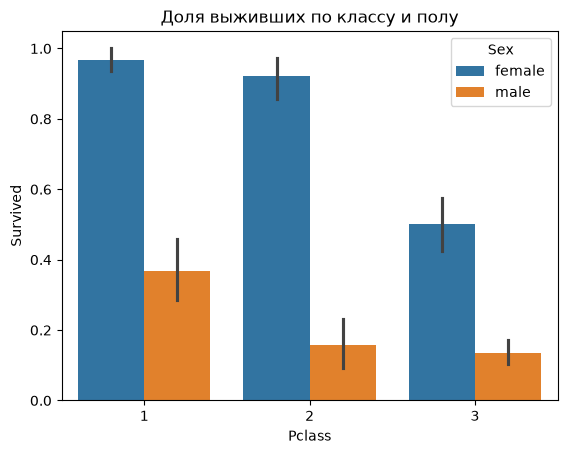

In [8]:
sns.barplot(data=train, x="Pclass", y="Survived", hue="Sex")
plt.title("Доля выживших по классу и полу")
plt.show()

## Класс и порт посадки
- Выживаемость по классам: 1 - ~63%, 2 - ~47%, 3 - ~24%
- Порт C (Шербур) - ~55%, S и Q - ниже. Сам порт вряд ли влиял: из Шербура садилось больше пассажиров 1 класса (проверено через `crosstab`)

In [12]:
train.groupby("Pclass")["Survived"].mean()

Pclass
1    0.629630
2    0.472826
3    0.242363
Name: Survived, dtype: float64

In [13]:
train.groupby("Embarked")["Survived"].mean()

Embarked
C    0.553571
Q    0.389610
S    0.336957
Name: Survived, dtype: float64

## Возраст
- Дети до ~6 лет выживали чаще, чем погибали - их спасали первыми
- Больше всего погибших в возрасте 20-32: в основном молодые мужчины 3 класса
- Пожилые (60+) почти все погибли
- Возраст сам по себе влияет слабее пола и класса, но детей важно выделить отдельно

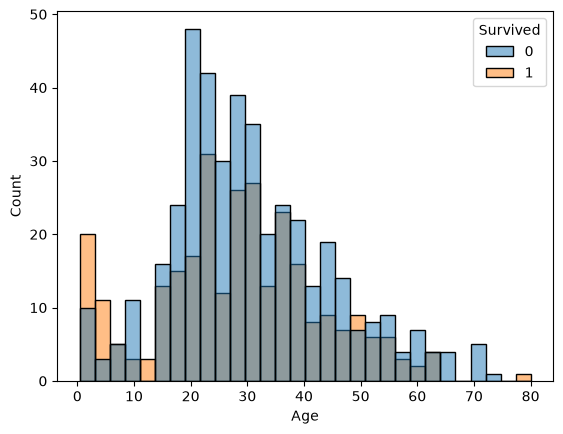

In [14]:
sns.histplot(data=train, x="Age", hue="Survived", bins=30)
plt.show()


## Выводы
1. Самые важные признаки: пол, класс, возраст (особенно «ребёнок или нет»)
2. Нужно обработать пропуски в `Age` и `Embarked`
3. Идеи для новых признаков: обращение из имени (Mr/Mrs/Miss/Master), размер семьи, «каюта известна»